In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from scipy.signal import lfilter, find_peaks

In [2]:
import pickle
from utils.pit.piece_wise_marginal import from_normal

waves_df = pd.read_csv("inputs/waves_bulk.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open("outputs/marginal/transformacion.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

#### ARX: dinámica en Z, con f (XGB, 04B) como entrada
z(t) = Σ φ_k z(t−k) + Σ γ_j f(t−j) + e(t)

Antes: z = f + r, con r un VAR → es el caso particular γ₀ = 1, γ_k = −φ_k. Aquí γ es libre: Z puede responder a f con inercia, y el ruido pasa por la misma dinámica que la señal.

In [3]:
resid = pd.read_csv("outputs/xgb_pit/residuos_horarios.csv", index_col=0, parse_dates=True)
z_all = resid.loc["1985-01-01":"2025-12-31", "z"].asfreq("h")
f_all = resid.loc["1985-01-01":"2025-12-31", "f"].asfreq("h")
hs_all = waves_df.loc["1985":"2025", "VHM0"]
print(z_all.isna().sum(), f_all.isna().sum(), len(z_all))

0 0 359400


In [4]:
#### Matriz de retardos: p retardos de z (1…p) y q+1 de f (0…q)
def matriz_arx(z, f, p, q):
    X = pd.concat({**{f"z{k}": z.shift(k) for k in range(1, p + 1)},
                   **{f"f{j}": f.shift(j) for j in range(0, q + 1)}}, axis=1)
    ok = X.notna().all(axis=1) & z.notna()
    return X[ok], z[ok]

tr = slice("1985-01-01", "2015-12-31")                      # f OOF en entrenamiento
filas = []
for p in [6, 12, 24, 48]:
    X, y = matriz_arx(z_all.loc[tr], f_all.loc[tr], p, p)
    beta, *_ = np.linalg.lstsq(X.values, y.values, rcond=None)
    e = y.values - X.values @ beta
    n, k = X.shape
    filas.append({"p = q": p, "std e": e.std(), "bic": n * np.log(e.var()) + k * np.log(n)})
print(pd.DataFrame(filas).set_index("p = q").round(4))

        std e           bic
p = q                      
6      0.0796 -1.375018e+06
12     0.0796 -1.375117e+06
24     0.0794 -1.375730e+06
48     0.0793 -1.375666e+06


In [5]:
p = q = 24                                                   # ← cambiar según el BIC
X, y = matriz_arx(z_all.loc[tr], f_all.loc[tr], p, q)
beta, *_ = np.linalg.lstsq(X.values, y.values, rcond=None)
phi, gam = beta[:p], beta[p:]
e_tr = pd.Series(y.values - X.values @ beta, index=y.index)

raices = np.abs(np.roots(np.r_[1, -phi]))
print(f"Σφ = {phi.sum():.3f} | Σγ = {gam.sum():.3f} | ganancia Σγ/(1−Σφ) = {gam.sum() / (1 - phi.sum()):.3f}")
print(f"máx |raíz| AR = {raices.max():.4f}  (< 1 → estable)")
print(f"std innovación = {e_tr.std():.3f}")

Σφ = 0.979 | Σγ = 0.020 | ganancia Σγ/(1−Σφ) = 0.974
máx |raíz| AR = 0.9390  (< 1 → estable)
std innovación = 0.079


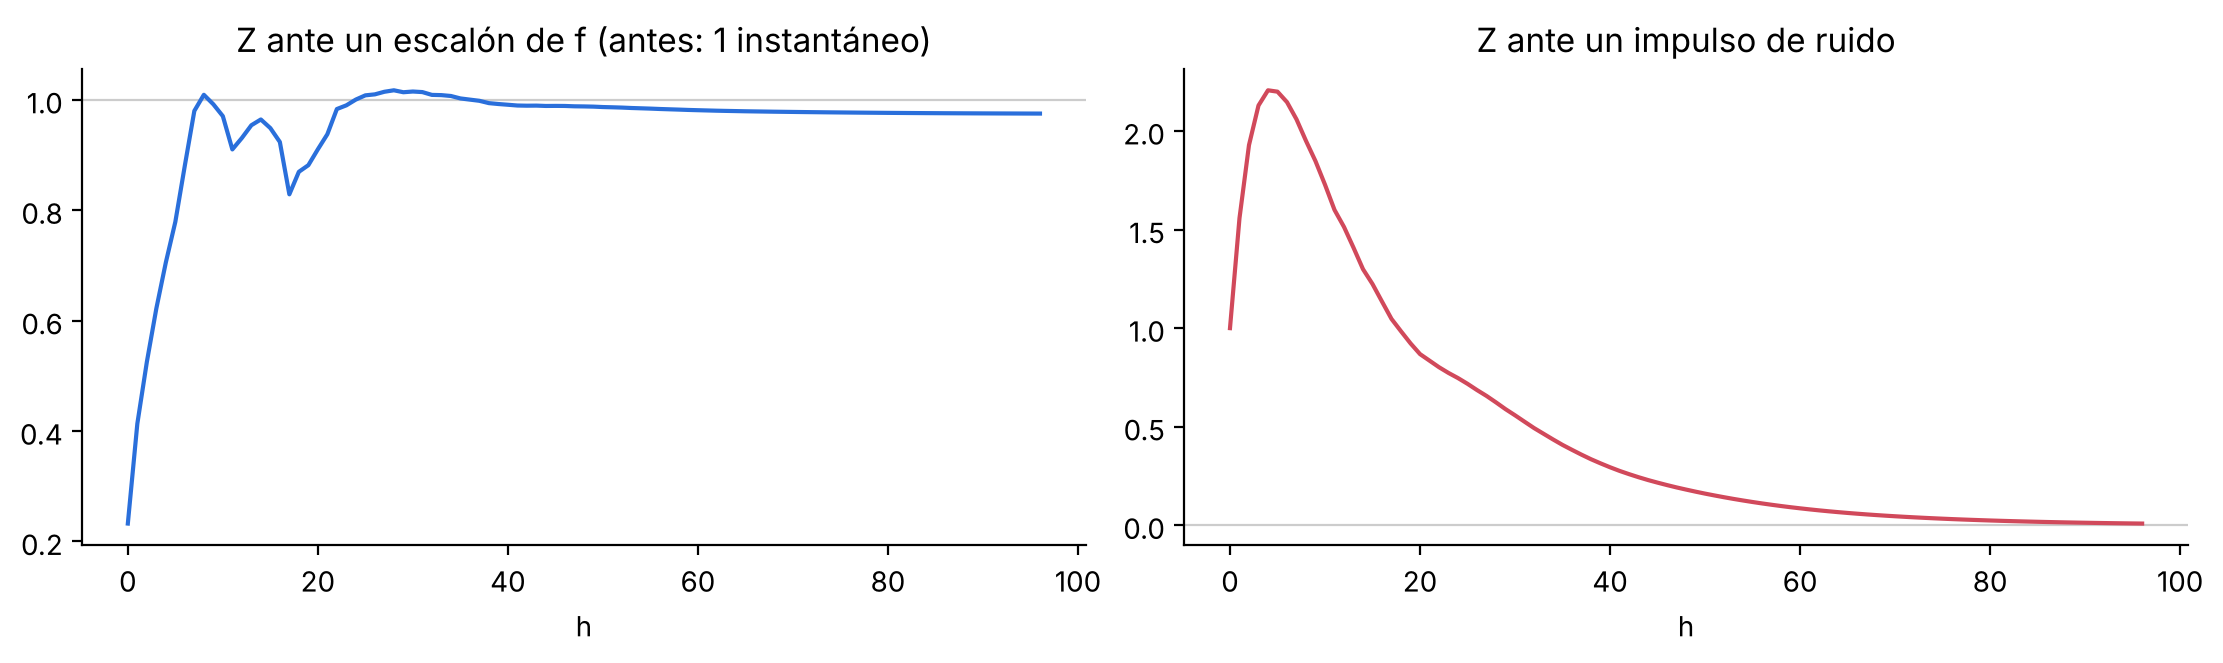

In [6]:
#### Respuesta de Z a un escalón de f (¿qué inercia aprende el modelo?) y a un impulso de ruido
h = np.arange(0, 97)
paso = lfilter(gam, np.r_[1, -phi], np.ones(len(h)))
imp = lfilter([1.0], np.r_[1, -phi], np.r_[1.0, np.zeros(len(h) - 1)])

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True)
axs[0].plot(h, paso, color="#2a6fdb", lw=1.5)
axs[0].axhline(1, color="0.8", lw=0.8, zorder=0)
axs[0].set(title="Z ante un escalón de f (antes: 1 instantáneo)", xlabel="h")
axs[1].plot(h, imp, color="#d1495b", lw=1.5)
axs[1].axhline(0, color="0.8", lw=0.8, zorder=0)
axs[1].set(title="Z ante un impulso de ruido", xlabel="h")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [7]:
#### Innovaciones: σ por decil de f (bordes de entrenamiento) y un solo pool estandarizado, en bloques
bordes = np.quantile(f_all.loc[tr], np.linspace(0, 1, 11)[1:-1])
dec_tr = np.digitize(f_all.reindex(e_tr.index), bordes)
sigma = e_tr.groupby(dec_tr).std()
print(sigma.round(3).values)

eps = (e_tr / sigma.loc[dec_tr].values).asfreq("h")
print(f"ACF de ε² en lag 1: {(eps**2).autocorr(1):.3f}")

L = 6
ev = eps.values
inicios = np.flatnonzero(np.convolve(~np.isnan(ev), np.ones(L), "valid") == L)

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

[0.082 0.088 0.083 0.08  0.076 0.077 0.08  0.079 0.077 0.071]
ACF de ε² en lag 1: 0.356


In [8]:
#### Simulación 1985–2025 con la f histórica: z = AR⁻¹( γ∗f + σ(f)·ε )
dec_all = np.digitize(f_all, bordes)
sig_all = sigma.loc[dec_all].values
entrada_f = lfilter(gam, [1.0], f_all.values)               # Σ γ_j f(t−j)
burn = 24 * 30

import time
n_sims = 30
hs_sims, z_sims = [], []
for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    x = entrada_f + sig_all * ruido_bloques(len(f_all), L, rng)
    x = np.r_[np.repeat(x[:burn].mean(), burn), x]          # arranque
    z_i = pd.Series(lfilter([1.0], np.r_[1, -phi], x)[burn:], index=f_all.index)
    z_sims.append(z_i)
    hs_sims.append(hs_desde_z(z_i))
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

hs_sims = pd.concat(hs_sims, axis=1)
z_sims = pd.concat(z_sims, axis=1)
hs_sims = hs_sims.loc["1985-02-01":]                          # fuera el primer mes (arranque)
z_sims = z_sims.loc["1985-02-01":]

sim 00 (0 s)


sim 01 (0 s)


sim 02 (0 s)


sim 03 (0 s)


sim 04 (0 s)


sim 05 (0 s)


... (20 outputs left out)

sim 26 (0 s)


sim 27 (0 s)


sim 28 (0 s)


sim 29 (0 s)


In [9]:
#### Temporales por década, mismo umbral y misma métrica que 05D
def n_picos(serie, umbral, sep_h=72):
    return len(find_peaks(serie.values, height=umbral, distance=sep_h)[0])

u = hs_all.quantile(0.99)
decadas = {"1985–1994": ("1985", "1994"), "1995–2004": ("1995", "2004"),
           "2005–2015": ("2005", "2015"), "2016–2025": ("2016", "2025")}
ref_05D = {"1985–1994": 67.0, "1995–2004": 71.5, "2005–2015": 80.9, "2016–2025": 71.0}   # f suavizada 13 h + escala + mapeo

filas = []
for nombre, (a, b) in decadas.items():
    n_anos = int(b) - int(a) + 1
    n_sim = [n_picos(hs_sims.loc[a:b, c_], u) * 10 / n_anos for c_ in hs_sims.columns]
    filas.append({"década": nombre, "obs": n_picos(hs_all.loc[a:b], u) * 10 / n_anos, "05D": ref_05D[nombre],
                  "ARX med": np.median(n_sim), "ARX lo": np.percentile(n_sim, 2.5), "ARX hi": np.percentile(n_sim, 97.5),
                  "q99 obs": hs_all.loc[a:b].quantile(0.99), "q99 ARX": hs_sims.loc[a:b].quantile(0.99).median()})
tabla_dec = pd.DataFrame(filas).set_index("década")
print(f"umbral común: {u:.2f} m  (temporales por cada 10 años)")
print(tabla_dec.round(2))

umbral común: 2.64 m  (temporales por cada 10 años)
             obs   05D  ARX med  ARX lo  ARX hi  q99 obs  q99 ARX
década                                                           
1985–1994  51.00  67.0    83.00   72.35   96.28     2.53     2.89
1995–2004  70.00  71.5    88.00   82.18   96.55     2.76     2.96
2005–2015  70.91  80.9   101.36   89.75  115.80     2.66     3.06
2016–2025  57.00  71.0    91.00   80.18   99.55     2.61     2.98


In [10]:
#### Test 2016–2025: cuantiles, máximo, cobertura y picos (como en 05C)
hs_obs = hs_all.loc["2016":"2025"]
w = hs_sims.loc["2016":"2025"]
st = pd.DataFrame({"q99": w.quantile(0.99), "q999": w.quantile(0.999), "max": w.max()})
print(f"obs: q99 {hs_obs.quantile(0.99):.2f} | q999 {hs_obs.quantile(0.999):.2f} | max {hs_obs.max():.2f}")
print(st.quantile([0.025, 0.5, 0.975]).round(2))

q_lo, q_hi = w.quantile(0.025, axis=1), w.quantile(0.975, axis=1)
o = hs_obs.reindex(w.index)
print(f"por encima {(o > q_hi).mean():.1%} | por debajo {(o < q_lo).mean():.1%}  (esperado 2,5 %)")

def picos(serie, umbral, sep_h=72):
    return serie.iloc[find_peaks(serie.values, height=umbral, distance=sep_h)[0]].values
u_t = hs_obs.quantile(0.99)
p_obs, p_sim = picos(hs_obs, u_t), [picos(w[c_], u_t) for c_ in w.columns]
n_sim = [len(p_) for p_ in p_sim]
print(f"nº temporales: obs {len(p_obs)} | sim {np.median(n_sim):.0f} [{np.percentile(n_sim, 2.5):.0f}–{np.percentile(n_sim, 97.5):.0f}]")
for q_ in [0.5, 0.9]:
    qs = [np.quantile(p_, q_) for p_ in p_sim]
    print(f"pico q{int(q_*100)}: obs {np.quantile(p_obs, q_):.2f} | sim {np.median(qs):.2f} [{np.percentile(qs, 2.5):.2f}–{np.percentile(qs, 97.5):.2f}]")

obs: q99 2.61 | q999 3.63 | max 5.50
        q99  q999   max
0.025  2.81  4.15  5.41
0.500  2.98  4.40  6.09
0.975  3.07  4.88  8.12
por encima 4.4% | por debajo 6.0%  (esperado 2,5 %)
nº temporales: obs 60 | sim 94 [83–104]
pico q50: obs 3.00 | sim 3.21 [3.11–3.38]
pico q90: obs 3.78 | sim 4.43 [4.24–4.83]


In [11]:
#### Autocorrelación de Z: obs vs ARX
lags_h = [1, 6, 12, 24, 48, 72]
print("obs ", [round(z_all.autocorr(l), 2) for l in lags_h])
print("ARX ", [round(np.median([z_sims[c_].autocorr(l) for c_ in z_sims.columns]), 2) for l in lags_h])
print(f"std Z: obs {z_all.std():.3f} | ARX {z_sims.std().median():.3f}")

obs  [np.float64(0.99), np.float64(0.89), np.float64(0.75), np.float64(0.53), np.float64(0.23), np.float64(0.11)]


ARX  [np.float64(0.99), np.float64(0.88), np.float64(0.73), np.float64(0.49), np.float64(0.19), np.float64(0.08)]
std Z: obs 0.995 | ARX 0.948


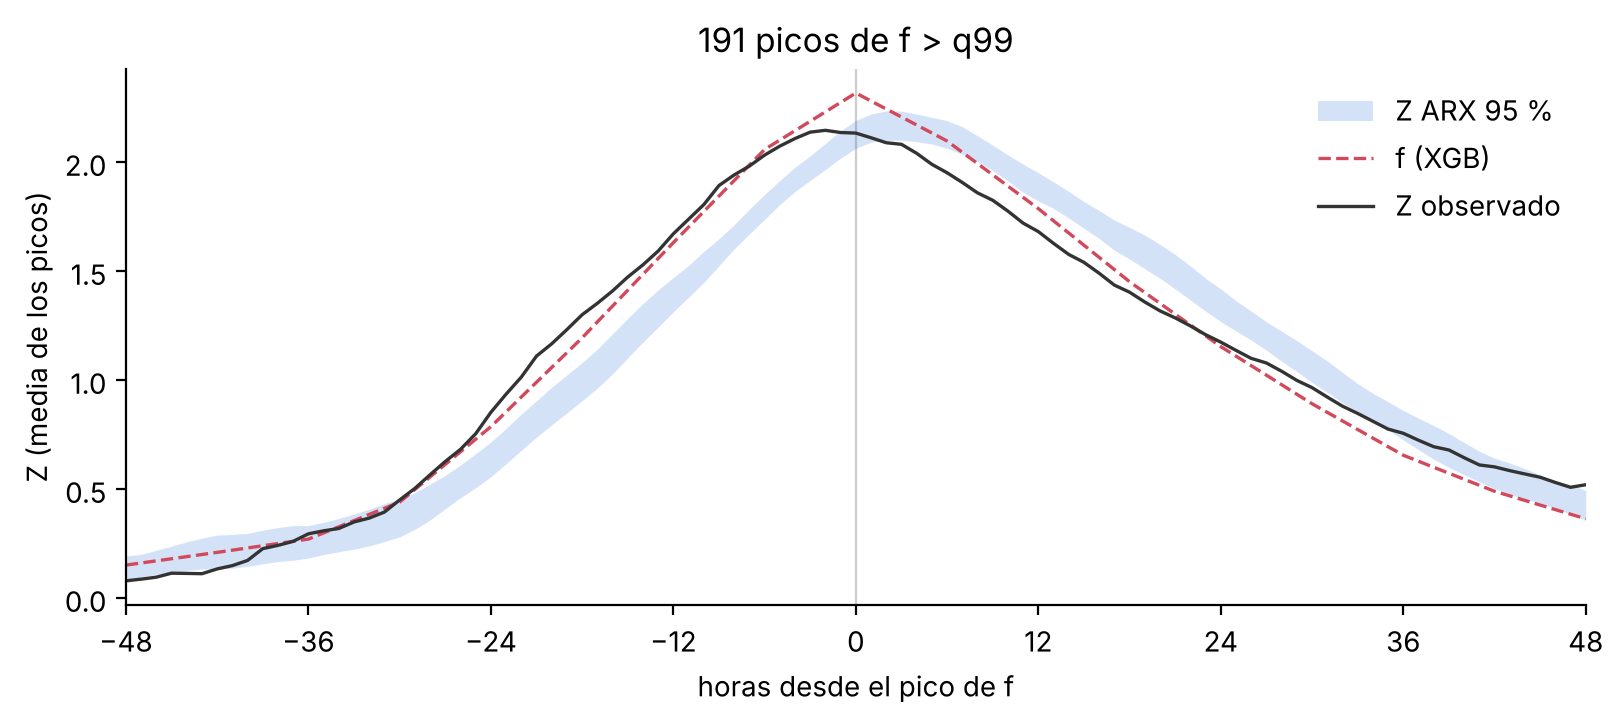

In [12]:
#### Composición alrededor de los picos de f (> q99): ¿el ARX reproduce el Z observado?
ventana = np.arange(-48, 49)
f_c = f_all.loc["1985-02-01":]
pk, _ = find_peaks(f_c.values, height=f_c.quantile(0.99), distance=72)
pk = pk[(pk > 48) & (pk < len(f_c) - 49)]

def compuesto(serie):
    return np.nanmean([serie.values[i + ventana] for i in pk], axis=0)

c_f, c_z = compuesto(f_c), compuesto(z_all.loc["1985-02-01":])
c_sim = np.array([compuesto(z_sims[c_]) for c_ in z_sims.columns])

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.fill_between(ventana, np.percentile(c_sim, 2.5, axis=0), np.percentile(c_sim, 97.5, axis=0),
                color="#2a6fdb", alpha=0.2, lw=0, label="Z ARX 95 %")
ax.plot(ventana, c_f, color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(ventana, c_z, color="0.2", lw=1.2, label="Z observado")
ax.axvline(0, color="0.8", lw=0.8, zorder=0)
ax.set(xlabel="horas desde el pico de f", ylabel="Z (media de los picos)", xticks=np.arange(-48, 49, 12), xlim=(-48, 48),
       title=f"{len(pk)} picos de f > q99")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

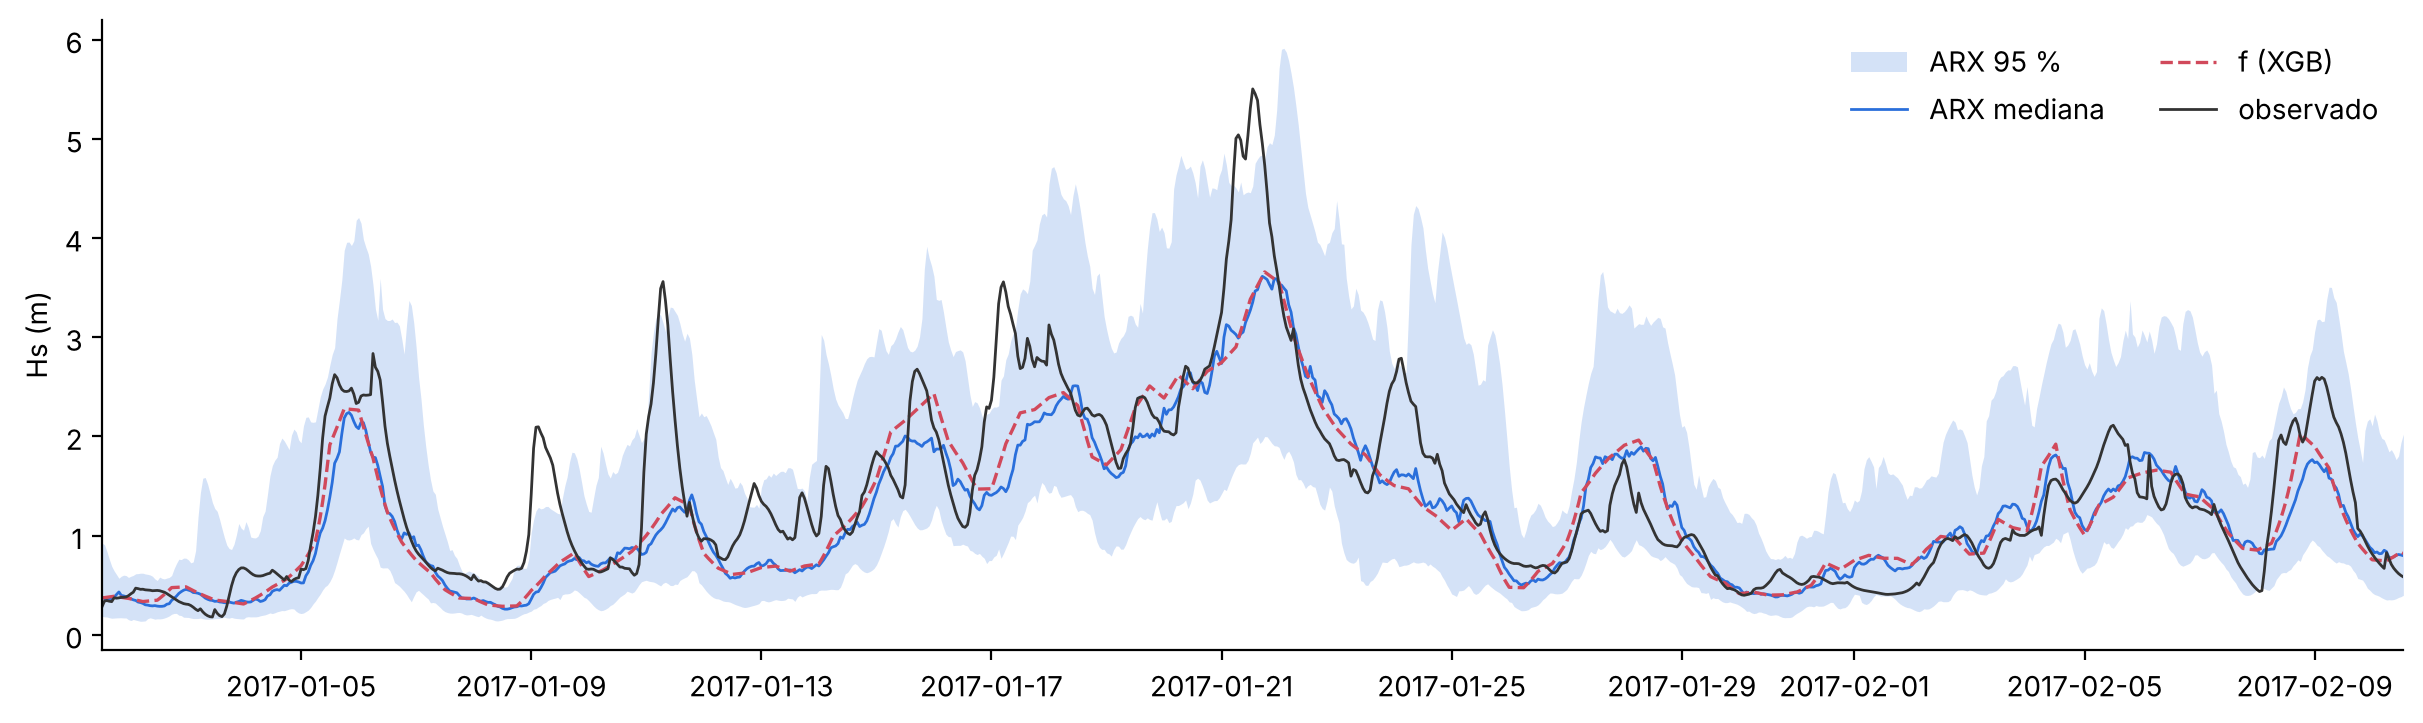

In [13]:
t_max = hs_obs.idxmax()
t0, t1 = t_max - pd.Timedelta(days=20), t_max + pd.Timedelta(days=20)
w_ = hs_sims.loc[t0:t1]

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(w_.index, w_.quantile(0.025, axis=1), w_.quantile(0.975, axis=1), color="#2a6fdb", alpha=0.2, lw=0, label="ARX 95 %")
ax.plot(w_.median(axis=1), color="#2a6fdb", lw=1, label="ARX mediana")
ax.plot(hs_desde_z(f_all.loc[t0:t1]), color="#d1495b", lw=1.2, ls="--", label="f (XGB)")
ax.plot(hs_obs.loc[t0:t1], color="0.2", lw=1, label="observado")
ax.set(ylabel="Hs (m)", xlim=(t0, t1))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.show()